In [1]:
suppressMessages(library(Seurat))
suppressMessages(library(cowplot))
suppressMessages(library(dplyr))
suppressMessages(library(harmony))

In [2]:
in_dir <- "../../results/02_10x_visium/05_integrate_data"
out_dir <- "../../results/02_10x_visium/07_integrate_data"

# create output directory if it doesn't exist
if (!dir.exists(out_dir)) {
  dir.create(out_dir, recursive = TRUE)
}

In [3]:
df_counts <- read.csv(glue::glue("{in_dir}/counts_matrix.csv"), row.names = 1)

In [4]:
df_meta <- read.csv(glue::glue("{in_dir}/obs.csv"), row.names = 1)

In [5]:
obj <- CreateSeuratObject(counts = t(df_counts), meta.data = df_meta)

Warning message:
“Data is of class matrix. Coercing to dgCMatrix.”


In [6]:
obj

An object of class Seurat 
18085 features across 19740 samples within 1 assay 
Active assay: RNA (18085 features, 0 variable features)
 1 layer present: counts

In [7]:
obj[["percent.mt"]] <- PercentageFeatureSet(obj, pattern = "^MT.")

Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”
Warning message:
“The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


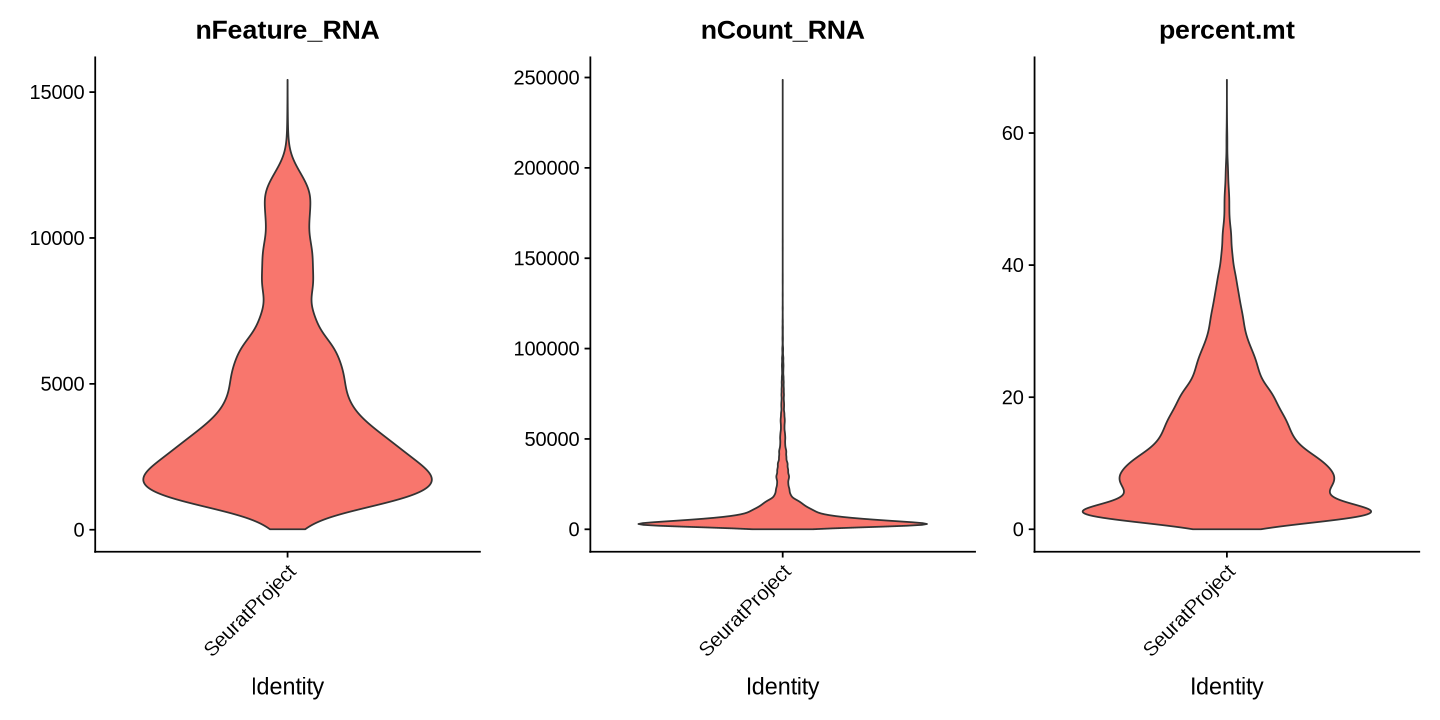

In [8]:
options(repr.plot.width=12, repr.plot.height=6)
VlnPlot(obj, features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), ncol = 3, pt.size = 0)

In [9]:
obj <- obj %>%
    NormalizeData() %>%
    FindVariableFeatures(selection.method = "vst", nfeatures = 2000) %>%
    ScaleData() %>%
    RunPCA(verbose = FALSE) %>%
    RunUMAP(dims = 1:30, verbose = FALSE, metric = "cosine")


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


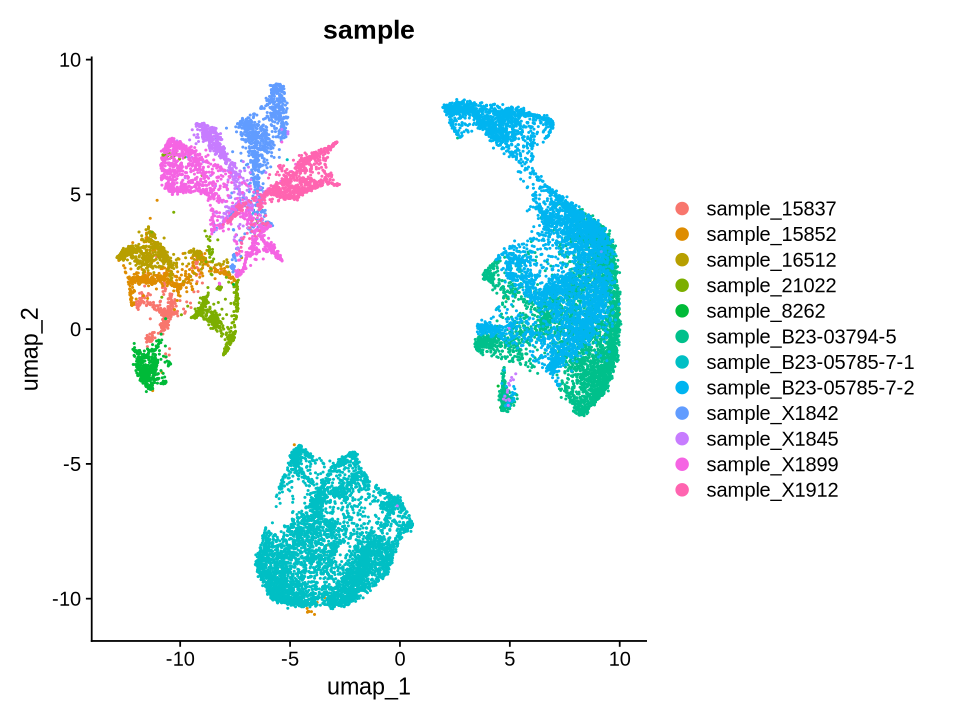

In [10]:
options(repr.plot.width=8, repr.plot.height=6)
DimPlot(obj, reduction = "umap", group.by = "sample")

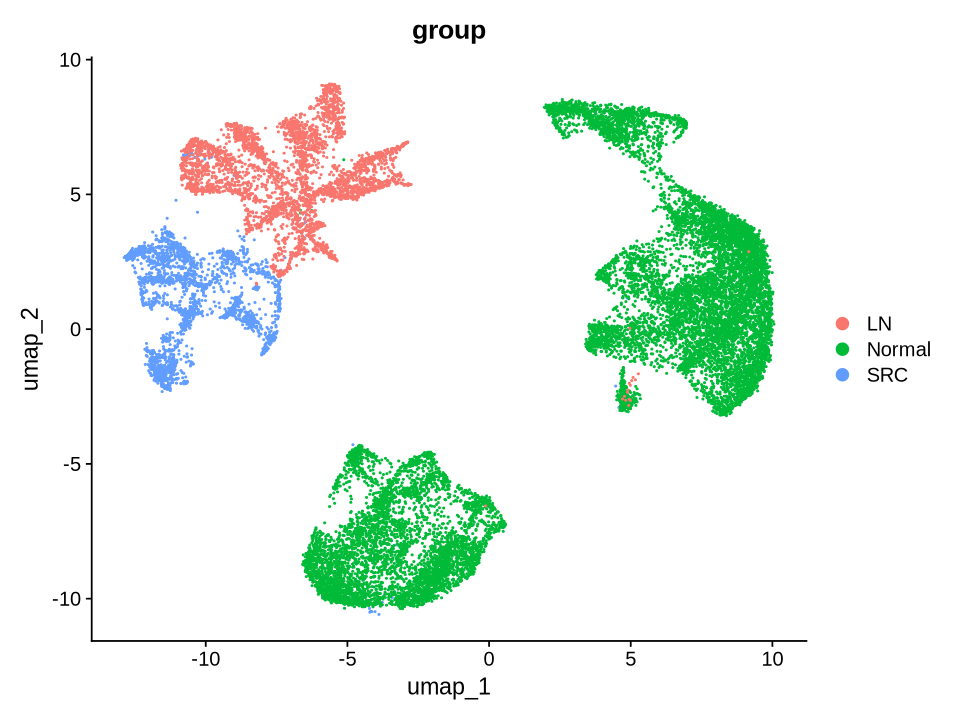

In [11]:
DimPlot(obj, reduction = "umap", group.by = "group")

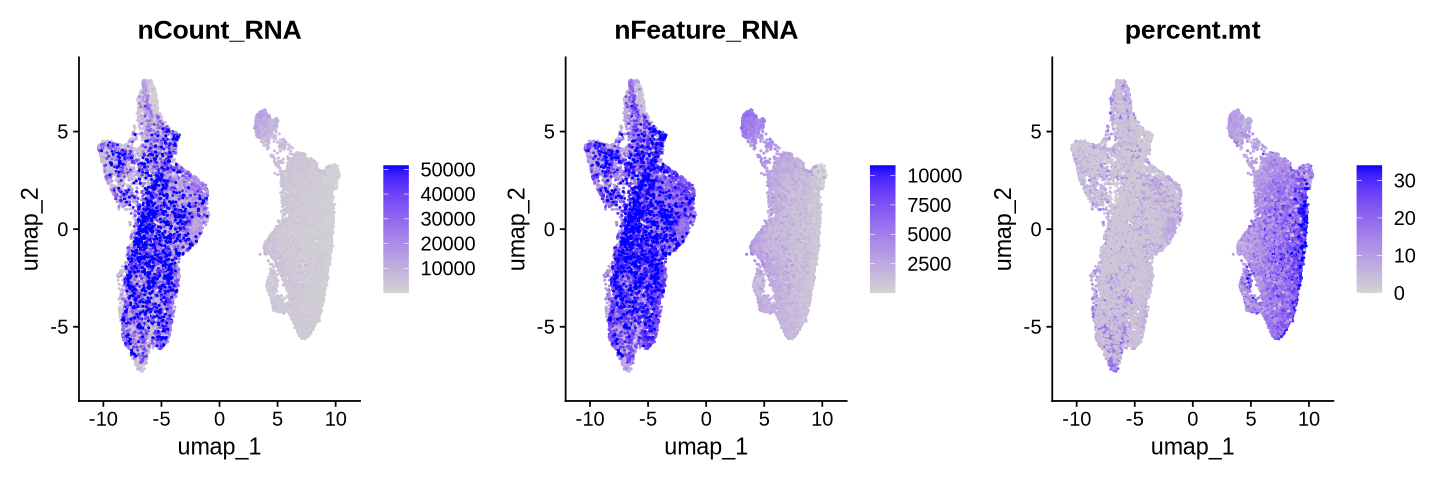

In [25]:
options(repr.plot.width=12, repr.plot.height=4)
FeaturePlot(obj, features = c("nCount_RNA", "nFeature_RNA", "percent.mt"), ncol = 3, max.cutoff = "q95")

Warning message:
“Warning: The parameter epsilon.harmony is deprecated. It will be ignored for this function call and please remove parameter epsilon.harmony in future function calls. If users want to control if harmony would stop early or not, use parameter early_stop. Advanced users can set value of parameter epsilon.harmony by using parameter .options and function harmony_options().
This warning is displayed once per session.”
Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/20

Harmony 2/20

Harmony 3/20

Harmony 4/20

Harmony 5/20

Harmony 6/20

Harmony 7/20

Harmony 8/20

Harmony 9/20

Harmony converged after 9 iterations

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


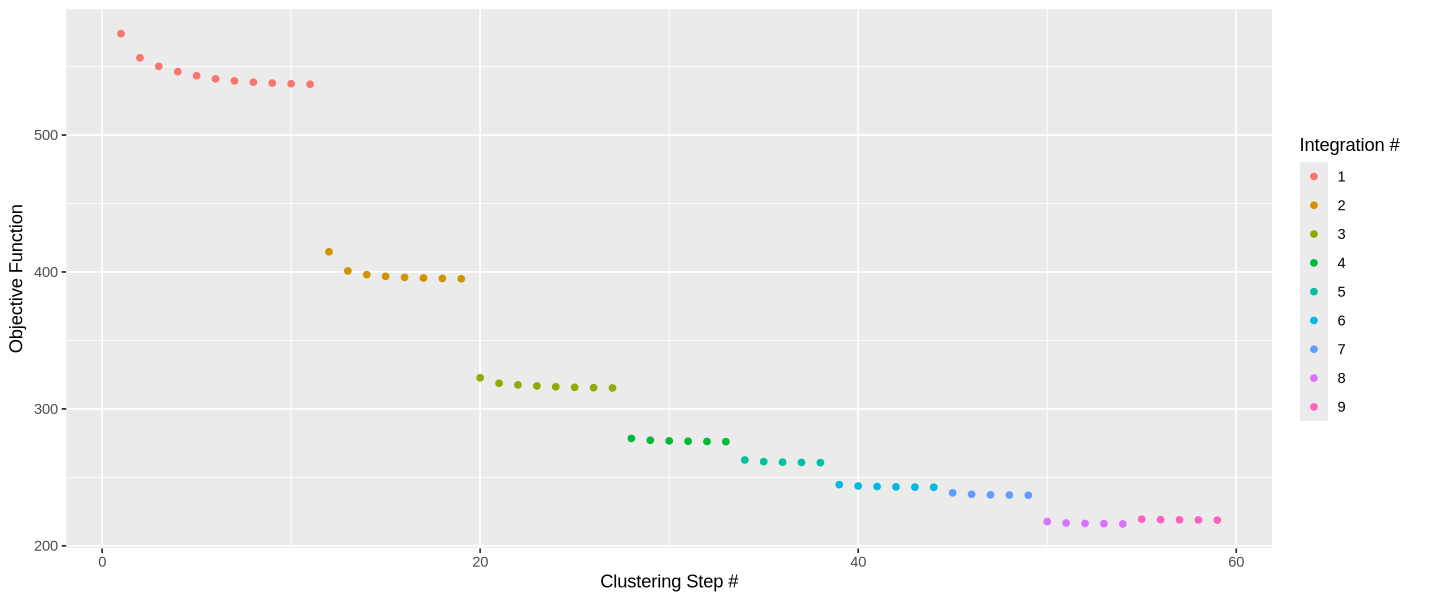

In [ ]:
obj <- RunHarmony(obj, group.by.vars = c("sample", "group"), plot_convergence = TRUE, 
dims.use = 1:10, max_iter = 20, epsilon.harmony = -1)

In [14]:
obj <- obj %>%
    RunUMAP(reduction = "harmony", dims = 1:10, verbose = FALSE)

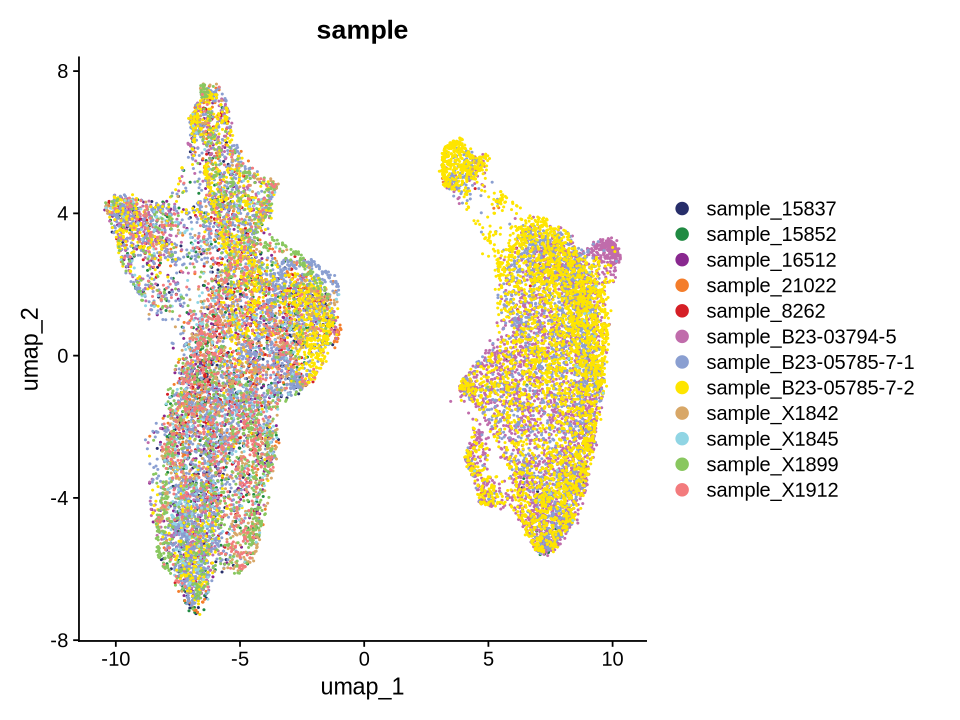

In [15]:
options(repr.plot.width=8, repr.plot.height=6)
DimPlot(obj, reduction = "umap", group.by = "sample", 
cols = ArchR::paletteDiscrete(obj@meta.data$sample))

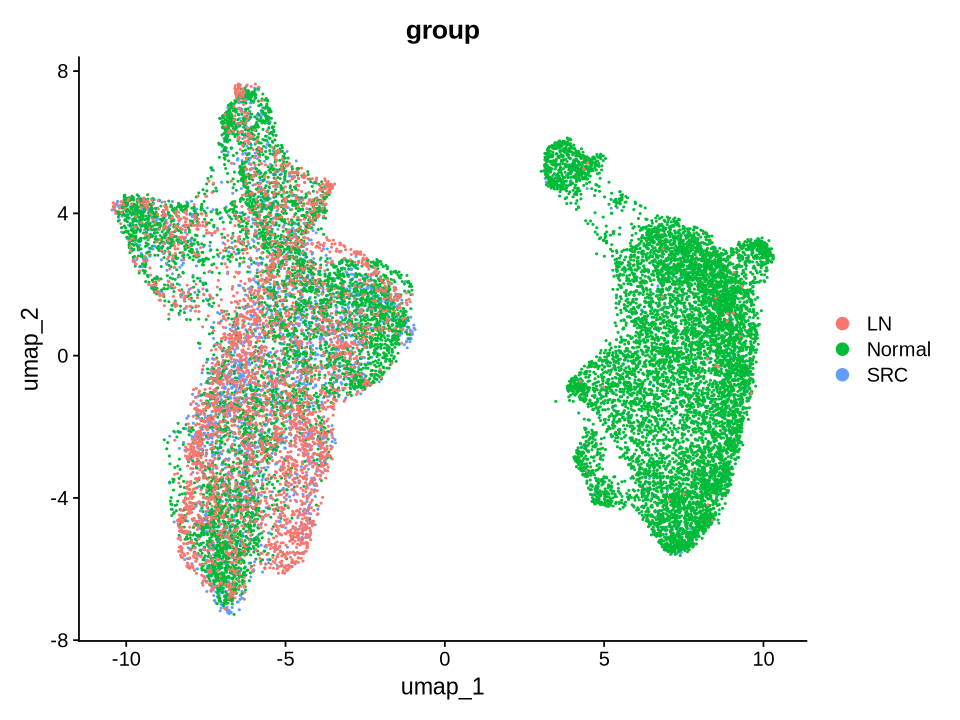

In [16]:
DimPlot(obj, reduction = "umap", group.by = "group")

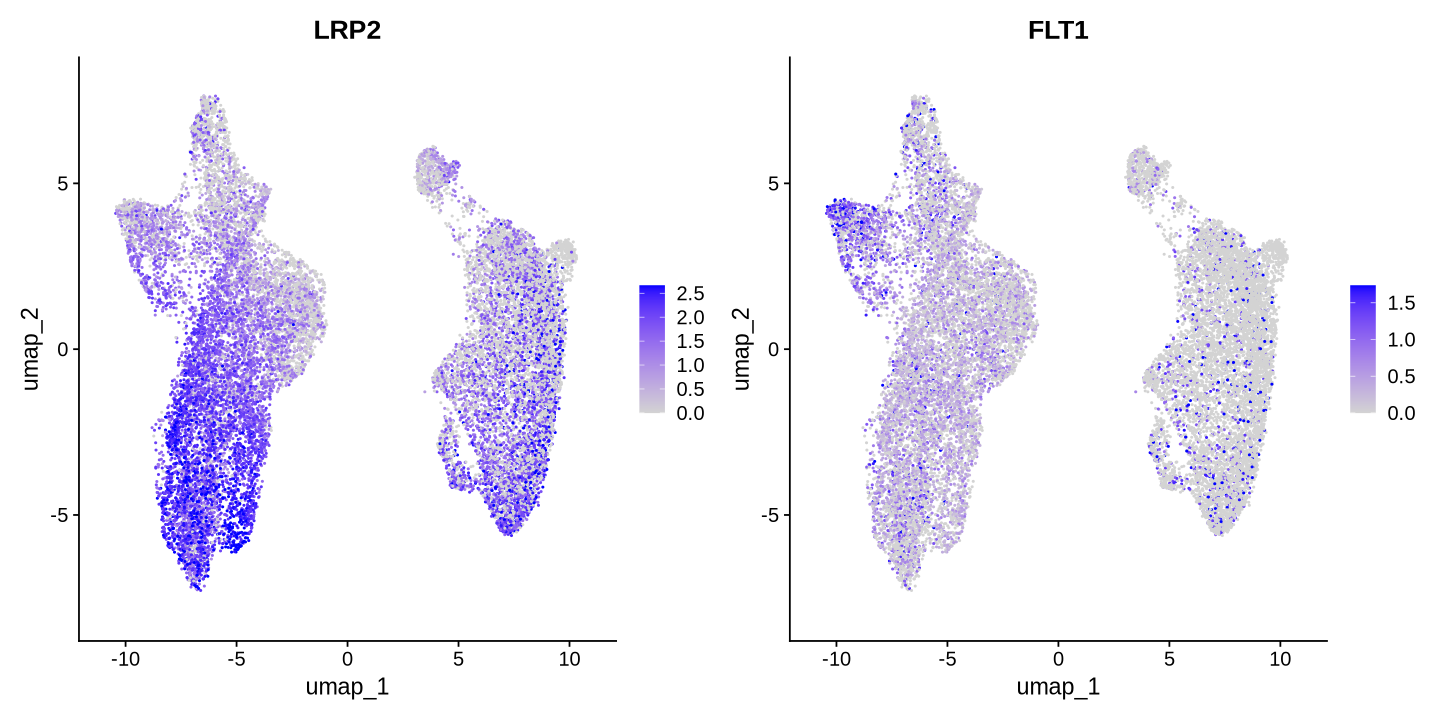

In [17]:
options(repr.plot.width=12, repr.plot.height=6)
FeaturePlot(obj, features = c("LRP2", "FLT1"), ncol = 2, max.cutoff = "q95")

In [18]:
colnames(obj@meta.data)

[1] "orig.ident"                  "nCount_RNA"                 
 [3] "nFeature_RNA"                "in_tissue"                  
 [5] "array_row"                   "array_col"                  
 [7] "sample"                      "n_genes_by_counts"          
 [9] "log1p_n_genes_by_counts"     "total_counts"               
[11] "log1p_total_counts"          "pct_counts_in_top_50_genes" 
[13] "pct_counts_in_top_100_genes" "pct_counts_in_top_200_genes"
[15] "pct_counts_in_top_500_genes" "group"                      
[17] "percent.mt"

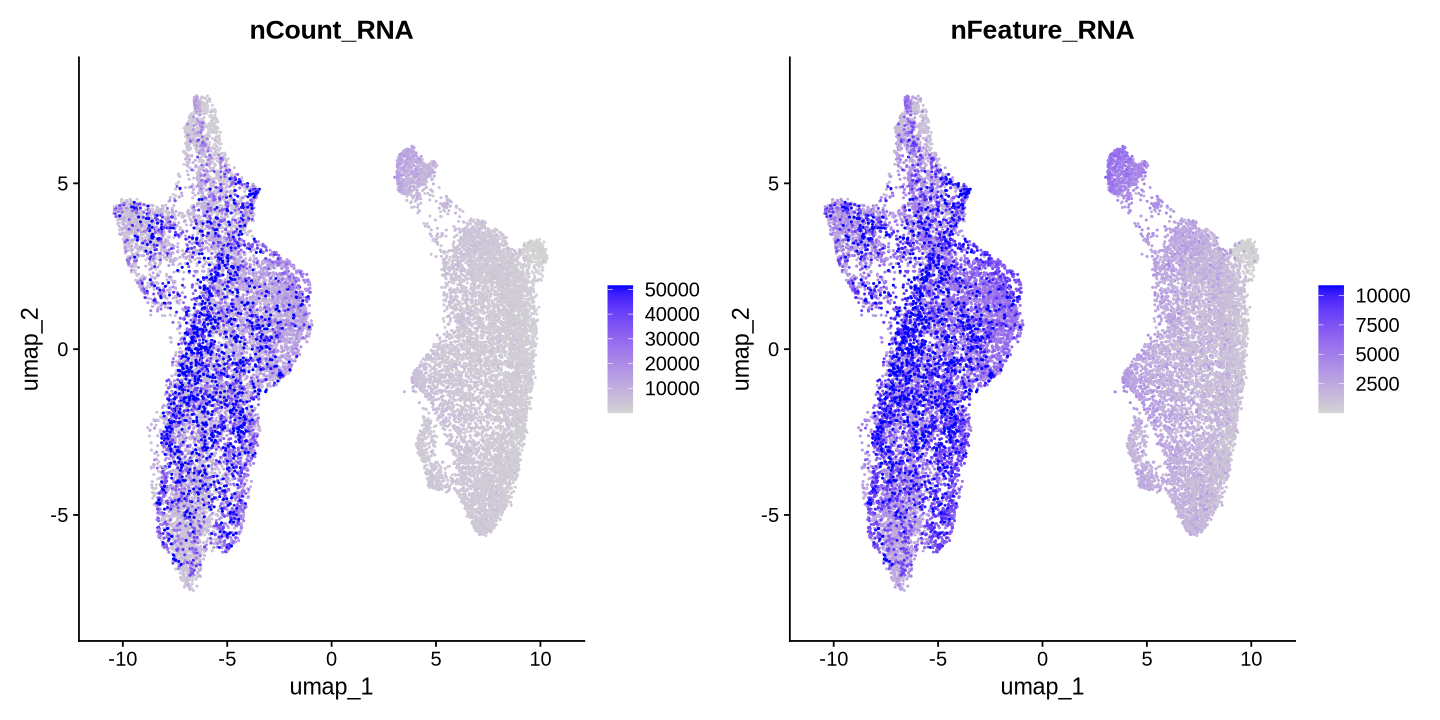

In [19]:
FeaturePlot(obj, features = c("nCount_RNA", "nFeature_RNA"), ncol = 2, max.cutoff = "q95")

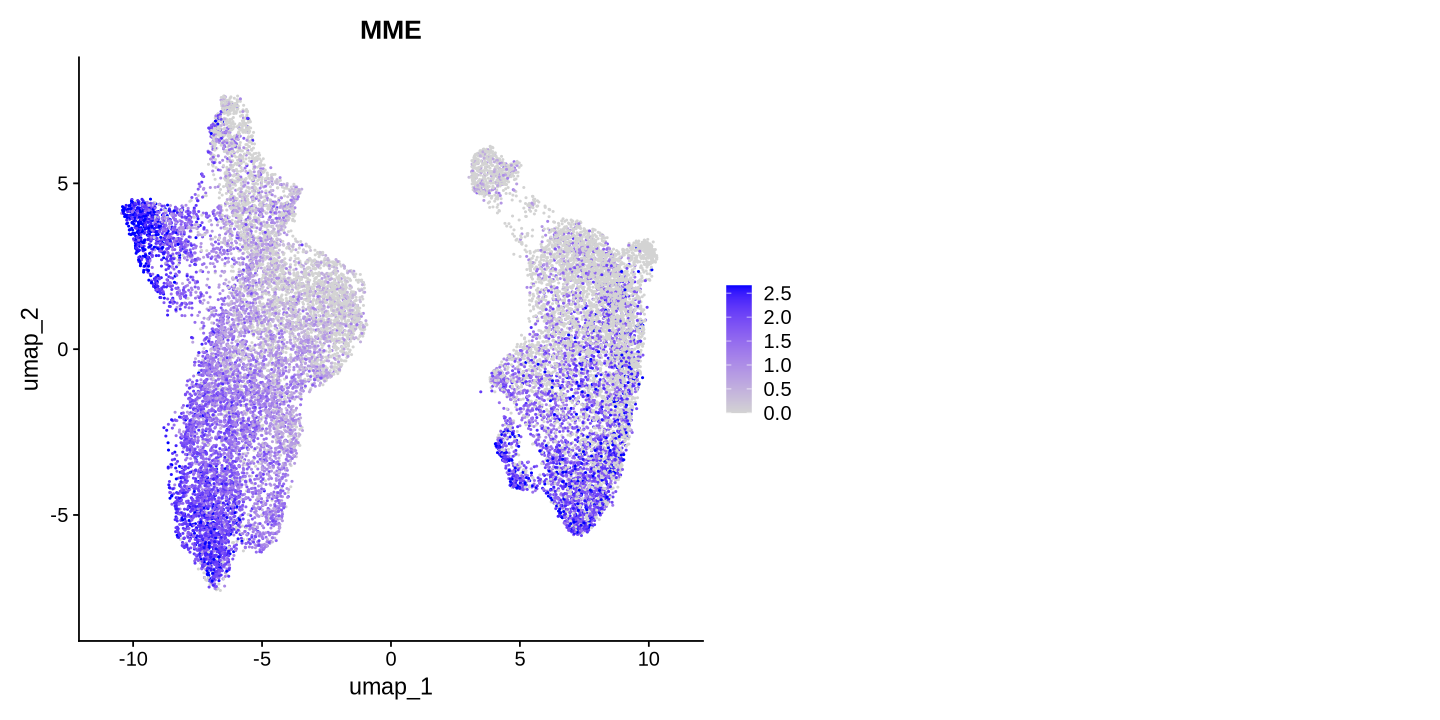

In [22]:
options(repr.plot.width=12, repr.plot.height=6)
FeaturePlot(obj, features = c("MME"), ncol = 2, max.cutoff = "q95")